# Error Analyisis
## Work Package 1
- We want to look which of the Dimension is most often filtered out from the models
- Which Dimensions are clustred togetehr most often
- We want to see what how many tokens often filtered oit sentences have (filler)
- We want also to know how many semantic cluster and how many snetences are filtered out

### How many Filler Sentences there are

In [1]:
import json

path_pre_processed = "data/pre_processed_modified_pbt_annotation_of_mini_session.json"
path_no_processed = "data/modified_pbt_annotation_of_mini_session (1).json"

with open(path_pre_processed) as f:
    data_processed = json.load(f)

with open(path_no_processed) as f:
    data = json.load(f)


In [2]:
import json
import os
from collections import Counter, defaultdict

def load_processes_by_session(json_data):
    process_map = {}
    session_map = defaultdict(list)
    for session_key, session_blocks in json_data.items():
        for block_index, block in enumerate(session_blocks):
            session_id = f"{session_key}_S{block_index + 1:02}"
            for process in block:
                pid = process["process_id"]
                process_map[pid] = (session_id, process)
                session_map[session_id].append(pid)
    return process_map, session_map

def analyze_filtered_processes(original_path, processed_path):
    """
    Analyze what was filtered out and summarize statistics.
    """
    # Load files
    with open(original_path, "r") as f:
        original_data = json.load(f)
    with open(processed_path, "r") as f:
        processed_data = json.load(f)

    # Build mappings
    original_map, original_sessions = load_processes_by_session(original_data)
    processed_map, _ = load_processes_by_session(processed_data)

    # Total counts
    total_processes = len(original_map)
    num_sessions = len(original_sessions)
    avg_processes_per_session = total_processes / num_sessions if num_sessions else 0

    # Filtered
    filtered_ids = set(original_map.keys()) - set(processed_map.keys())
    filtered_items = [original_map[pid][1] for pid in filtered_ids]
    percent_filtered = (len(filtered_items) / total_processes) * 100 if total_processes else 0

    # Token length
    token_lengths = [len(p["process"].split()) for p in filtered_items]
    avg_token_len = sum(token_lengths) / len(token_lengths) if token_lengths else 0

    # Dimensions
    all_dimensions = [dim for p in filtered_items for dim in p.get("dimensions", [])]
    dimension_counts = Counter(all_dimensions)

    # Filtered counts per session
    session_filtered_counts = defaultdict(int)
    for pid in filtered_ids:
        session_id, _ = original_map[pid]
        session_filtered_counts[session_id] += 1
    avg_filtered_per_session = (
        sum(session_filtered_counts.values()) / len(session_filtered_counts)
        if session_filtered_counts else 0
    )

    # Print summary
    print("\n=== Filtered Analysis Summary ===")
    print(f"Total sessions: {num_sessions}")
    print(f"Total processes: {total_processes}")
    print(f"Total filtered: {len(filtered_items)}")
    print(f"→ Percentage filtered: {round(percent_filtered, 2)}%")
    print(f"Average processes per session: {round(avg_processes_per_session, 2)}")
    print(f"Average filtered per session: {round(avg_filtered_per_session, 2)}")
    print(f"Average token length of filtered sentences: {round(avg_token_len, 2)}")
    print("Dimensions in filtered sentences:")
    for dim, count in dimension_counts.items():
        print(f"  • {dim}: {count}")

     # New: total counts for comparison
    original_dimensions = [dim for _, process in original_map.values() for dim in process.get("dimensions", [])]
    total_dimension_counts = Counter(original_dimensions)

    print("Total processes per dimension (before filtering):")
    for dim, count in total_dimension_counts.items():
        print(f"  • {dim}: {count}")

    return filtered_ids, original_map



def print_filtered_sentences(filtered_ids, original_map):
    """
    Print all filtered-out sentences with session and process IDs.
    """
    print("\n=== Filtered-out Sentences ===")
    for pid in sorted(filtered_ids):
        session_id, process = original_map[pid]
        sentence = process.get("process", "[NO TEXT]")
        print(f"[{session_id}] {pid}: {sentence}")



filtered_ids, original_map = analyze_filtered_processes("data/modified_pbt_annotation_of_mini_session (1).json", "data/pre_processed_modified_pbt_annotation_of_mini_session.json")
print_filtered_sentences(filtered_ids, original_map)







=== Filtered Analysis Summary ===
Total sessions: 77
Total processes: 4153
Total filtered: 793
→ Percentage filtered: 19.09%
Average processes per session: 53.94
Average filtered per session: 10.72
Average token length of filtered sentences: 10.13
Dimensions in filtered sentences:
  • Cognition: 487
  • Attention: 74
  • (Overt) Behaviour: 155
  • Sense of Self: 22
  • Context/Moderators: 68
  • Sociocultural: 57
  • Motivation: 21
  • Biophysiological: 15
  • Affect: 64
Total processes per dimension (before filtering):
  • Cognition: 2323
  • Sense of Self: 285
  • (Overt) Behaviour: 987
  • Affect: 445
  • Context/Moderators: 480
  • Attention: 342
  • Biophysiological: 111
  • Sociocultural: 470
  • Motivation: 258

=== Filtered-out Sentences ===
[P11_S10] p11_10_12: I was like, growing up, but yeah.
[P11_S10] p11_10_13: But that, yeah, just thinking about it now, just like, what?
[P11_S10] p11_10_19: I don't even know.
[P11_S10] p11_10_26: It's not like, oh, like, I want to be sma

## Generating Tabel for filtered analysis

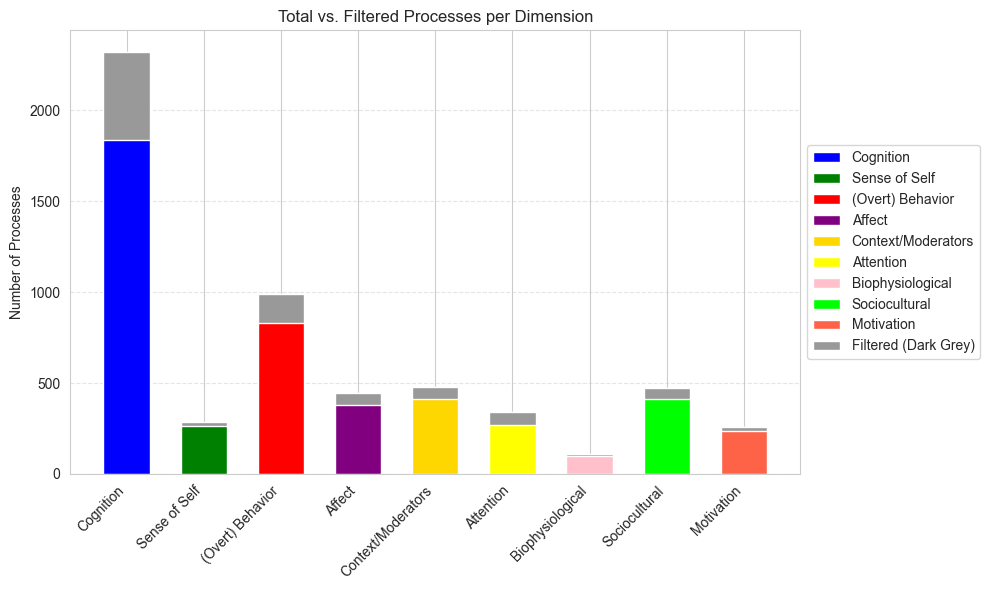

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

# Data
dimensions = [
    "Cognition", "Sense of Self", "(Overt) Behavior", "Affect",
    "Context/Moderators", "Attention", "Biophysiological", "Sociocultural", "Motivation"
]
total_counts = [2323, 285, 987, 445, 480, 342, 111, 470, 258]
filtered_counts = [487, 22, 155, 64, 68, 74, 15, 57, 21]

# Matched colors from your legend
base_colors = {
    "Cognition": "#0000FF",           # Blue
    "Sense of Self": "#008000",       # Green
    "(Overt) Behavior": "#FF0000",   # Red
    "Affect": "#800080",              # Purple
    "Context/Moderators": "#FFD700",  # Yellow-Orange
    "Attention": "#FFFF00",           # Bright Yellow
    "Biophysiological": "#FFC0CB",    # Pink
    "Sociocultural": "#00FF00",       # Neon Green
    "Motivation": "#FF6347",          # Orange-Red
}

# Grey for filtered overlay
filtered_color = "#999999"  # Dark grey

# Plot setup
x = np.arange(len(dimensions))
width = 0.6

fig, ax = plt.subplots(figsize=(10, 6))

# Plot total bars
for i, dim in enumerate(dimensions):
    ax.bar(x[i], total_counts[i], width, color=base_colors[dim], zorder=1)

# Overlay filtered counts as grey bars
for i, dim in enumerate(dimensions):
    ax.bar(
        x[i],
        filtered_counts[i],
        width,
        color=filtered_color,
        bottom=total_counts[i] - filtered_counts[i],
        zorder=2
    )

# Axis setup
ax.set_xticks(x)
ax.set_xticklabels(dimensions, rotation=45, ha='right')
ax.set_ylabel('Number of Processes')
ax.set_title('Total vs. Filtered Processes per Dimension')
ax.grid(True, axis='y', linestyle='--', alpha=0.5, zorder=0)

# Custom legend: one per dimension + one for filtered
legend_elements = [Patch(facecolor=base_colors[dim], label=dim) for dim in dimensions]
legend_elements.append(Patch(facecolor=filtered_color, label="Filtered (Dark Grey)"))
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.0, 0.5))

fig.tight_layout()

# Save to PDF
plt.savefig("dimension_filter_analysis.pdf", format="pdf")
plt.show()


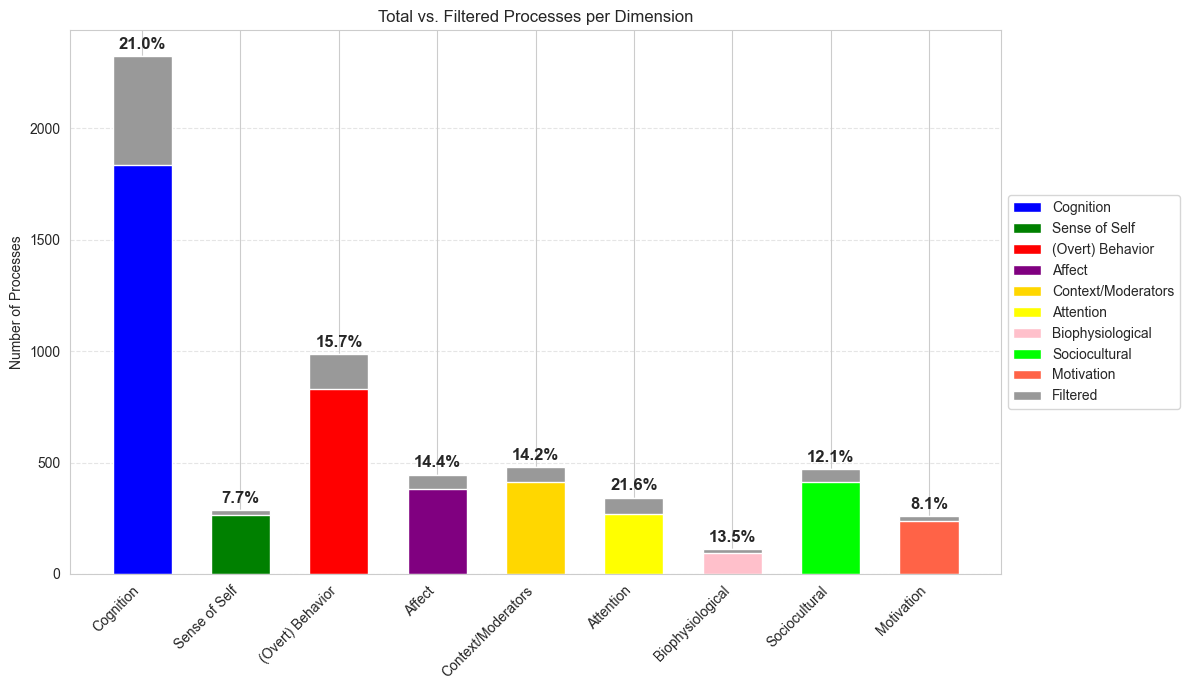

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

# Data
dimensions = [
    "Cognition", "Sense of Self", "(Overt) Behavior", "Affect",
    "Context/Moderators", "Attention", "Biophysiological", "Sociocultural", "Motivation"
]
total_counts = [2323, 285, 987, 445, 480, 342, 111, 470, 258]
filtered_counts = [487, 22, 155, 64, 68, 74, 15, 57, 21]

# Matched colors from your legend
base_colors = {
    "Cognition": "#0000FF",           # Blue
    "Sense of Self": "#008000",       # Green
    "(Overt) Behavior": "#FF0000",    # Red
    "Affect": "#800080",              # Purple
    "Context/Moderators": "#FFD700",  # Yellow-Orange
    "Attention": "#FFFF00",           # Bright Yellow
    "Biophysiological": "#FFC0CB",    # Pink
    "Sociocultural": "#00FF00",       # Neon Green
    "Motivation": "#FF6347",          # Orange-Red
}

# Grey for filtered overlay
filtered_color = "#999999"  # Dark grey

# Plot setup
x = np.arange(len(dimensions))
width = 0.6

fig, ax = plt.subplots(figsize=(12, 7))

# Plot total bars
for i, dim in enumerate(dimensions):
    ax.bar(x[i], total_counts[i], width, color=base_colors[dim], zorder=1)

# Overlay filtered counts as grey bars
for i, dim in enumerate(dimensions):
    ax.bar(
        x[i],
        filtered_counts[i],
        width,
        color=filtered_color,
        bottom=total_counts[i] - filtered_counts[i],
        zorder=2
    )

# Annotate with percentage of filtered (removed)
# Annotate with percentage of filtered (removed)
for i in range(len(dimensions)):
    percent = (filtered_counts[i] / total_counts[i]) * 100
    ax.text(
        x[i],
        total_counts[i] + 20,  # slightly above bar
        f"{percent:.1f}%",
        ha='center',
        va='bottom',
        fontsize=12,  # Larger font size
        fontweight='bold',
        zorder=3
    )


# Axis setup
ax.set_xticks(x)
ax.set_xticklabels(dimensions, rotation=45, ha='right')
ax.set_ylabel('Number of Processes')
ax.set_title('Total vs. Filtered Processes per Dimension')
ax.grid(True, axis='y', linestyle='--', alpha=0.5, zorder=0)

# Custom legend: one per dimension + one for filtered
legend_elements = [Patch(facecolor=base_colors[dim], label=dim) for dim in dimensions]
legend_elements.append(Patch(facecolor=filtered_color, label="Filtered"))
ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.0, 0.5))

fig.tight_layout()

# Save to PDF
plt.savefig("dimension_filter_analysis_with_percentages.pdf", format="pdf")
plt.show()


In [8]:
import json
from collections import defaultdict, Counter
from statistics import mean

def analyze_semantic_clusters(processed_path):
    """
    Analyze semantic clusters:
      - Multi-sentence cluster count
      - Average cluster size (multi only)
      - Avg multi-clusters per session
      - Self-dimension & cross-dimension cluster stats

    Args:
        processed_path (str): Path to processed JSON file.

    Returns:
        dict: Analysis summary.
    """
    with open(processed_path, "r") as f:
        data = json.load(f)

    cluster_sizes = []
    same_dimension_counts = Counter()
    cross_dimension_counts = Counter()
    multi_cluster_per_session = []
    sessions_analyzed = 0

    for session_key, session_blocks in data.items():
        for block_index, block in enumerate(session_blocks):
            session_id = f"{session_key}_S{block_index + 1:02}"
            sessions_analyzed += 1
            session_multi_cluster_count = 0

            # Group by cluster
            cluster_map = defaultdict(list)
            for process in block:
                cluster = process.get("semantic_cluster")
                if cluster is not None:
                    cluster_map[cluster].append(process)

            for processes in cluster_map.values():
                if len(processes) <= 1:
                    continue

                session_multi_cluster_count += 1
                cluster_sizes.append(len(processes))

                # Same-dimension clustering
                dims = [d for p in processes for d in p.get("dimensions", [])]
                dim_counts = Counter(dims)
                for dim, count in dim_counts.items():
                    if count > 1:
                        same_dimension_counts[dim] += 1

                # Cross-dimension clustering
                unique_dims = set(dims)
                if len(unique_dims) > 1:
                    for d1 in unique_dims:
                        for d2 in unique_dims:
                            if d1 != d2:
                                pair = tuple(sorted((d1, d2)))
                                cross_dimension_counts[pair] += 1

            multi_cluster_per_session.append(session_multi_cluster_count)

    avg_cluster_size = round(mean(cluster_sizes), 2) if cluster_sizes else 0
    avg_multi_clusters_per_session = round(mean(multi_cluster_per_session), 2) if multi_cluster_per_session else 0
    total_multi_clusters = sum(multi_cluster_per_session)

    # Print summary
    print("\n=== Semantic Cluster Analysis ===")
    print(f"Sessions analyzed: {sessions_analyzed}")
    print(f"Total multi-sentence clusters: {total_multi_clusters}")
    print(f"Average size of multi-sentence clusters: {avg_cluster_size}")
    print(f"Average multi-sentence clusters per session: {avg_multi_clusters_per_session}")

    print("\nDimensions often clustered with themselves:")
    for dim, count in same_dimension_counts.most_common():
        print(f"  • {dim}: {count} clusters")

    print("\nTop cross-dimension combinations:")
    for (d1, d2), count in cross_dimension_counts.most_common(10):
        print(f"  • {d1} + {d2}: {count} clusters")

    return {
        "sessions_analyzed": sessions_analyzed,
        "total_multi_sentence_clusters": total_multi_clusters,
        "average_cluster_size": avg_cluster_size,
        "average_multi_clusters_per_session": avg_multi_clusters_per_session,
        "same_dimension_clusters": dict(same_dimension_counts),
        "cross_dimension_clusters": dict(cross_dimension_counts),
    }

cluster_summary = analyze_semantic_clusters("data/pre_processed_modified_pbt_annotation_of_mini_session.json")


=== Semantic Cluster Analysis ===
Sessions analyzed: 77
Total multi-sentence clusters: 457
Average size of multi-sentence clusters: 2.13
Average multi-sentence clusters per session: 5.94

Dimensions often clustered with themselves:
  • Cognition: 201 clusters
  • (Overt) Behaviour: 62 clusters
  • Affect: 42 clusters
  • Sociocultural: 32 clusters
  • Context/Moderators: 25 clusters
  • Motivation: 19 clusters
  • Sense of Self: 18 clusters
  • Attention: 18 clusters
  • Biophysiological: 15 clusters

Top cross-dimension combinations:
  • (Overt) Behaviour + Cognition: 192 clusters
  • Cognition + Sociocultural: 122 clusters
  • Cognition + Context/Moderators: 104 clusters
  • Affect + Cognition: 94 clusters
  • Attention + Cognition: 90 clusters
  • Cognition + Sense of Self: 88 clusters
  • Cognition + Motivation: 70 clusters
  • (Overt) Behaviour + Sociocultural: 66 clusters
  • (Overt) Behaviour + Context/Moderators: 54 clusters
  • (Overt) Behaviour + Attention: 48 clusters


## Calculation completness

In [7]:
from collections import defaultdict

def print_session_processes_sorted_by_cluster(session_id, json_data):
    """
    Gibt alle Prozesse einer Session gruppiert nach semantic_cluster aus.

    Args:
        session_id (str): Session-ID, z. B. "P15_S01"
        json_data (dict): JSON-Datenstruktur
    """
    session_key, block_num_str = session_id.split("_S")
    block_index = int(block_num_str) - 1

    if session_key not in json_data:
        print(f"Session key '{session_key}' nicht gefunden.")
        return

    try:
        block = json_data[session_key][block_index]
    except IndexError:
        print(f"Block-Index {block_index} nicht vorhanden in Session '{session_key}'.")
        return

    print(f"\n=== Prozesse in Session: {session_id} (gruppiert nach semantic_cluster) ===")

    cluster_map = defaultdict(list)

    for process in block:
        cluster = process.get("semantic_cluster", "N/A")
        cluster_map[cluster].append(process)

    # Sortiert nach Cluster-ID (Zahlen zuerst, dann evtl. "N/A")
    sorted_clusters = sorted(cluster_map.keys(), key=lambda x: (9999 if x == "N/A" else x))

    for cluster in sorted_clusters:
        print(f"\n--- Cluster {cluster} ---")
        for process in cluster_map[cluster]:
            pid = process.get("process_id", "[NO ID]")
            text = process.get("process", "[NO TEXT]")
            print(f"[{pid}] {text}")

    total_processes = len(block)
    total_clusters = len(cluster_map)

    print(f"\n▶ Gesamtanzahl Prozesse: {total_processes}")
    print(f"▶ Anzahl eindeutiger semantic_cluster: {total_clusters} → {sorted_clusters}")



print_session_processes_sorted_by_cluster("P11_S09",data_processed)


=== Prozesse in Session: P11_S09 (gruppiert nach semantic_cluster) ===

--- Cluster 0 ---
[p11_9_5] She said, I'm so excited for it.
[p11_9_8] I'm excited.

--- Cluster 1 ---
[p11_9_17] I would say never, but I can't really think of a time where I'm trying looking at things that way.

--- Cluster 2 ---
[p11_9_18] I want to try to see it.

--- Cluster 3 ---
[p11_9_16] It's also the anxious side.

--- Cluster 4 ---
[p11_9_6] I believe you.

--- Cluster 5 ---
[p11_9_14] So I was happy for her.

--- Cluster 6 ---
[p11_9_11] set down my anxious thoughts and forward with it.

--- Cluster 7 ---
[p11_9_12] It was really just an instance of when my girlfriend said she had a really good time gone.

--- Cluster 8 ---
[p11_9_15] So I know it's a good thing.

--- Cluster 9 ---
[p11_9_4] Wanting to just say, just forget the surprises.

--- Cluster 10 ---
[p11_9_2] Yeah, I would say so.

--- Cluster 11 ---
[p11_9_10] I don't know the joke, but just being honest and saying that the joke, I just thoug

# calculating Correlation and F1-Agreement


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import f1_score
#df = pd.read_csv('correlation_2.csv')
df = pd.read_csv('faith.csv')

label_mapping = {'Unfaithfull': 0, 'Faithfull': 1}
human_scores = [label_mapping[label] for label in df['llm'].tolist()]
llm_scores = [label_mapping[label] for label in df['human'].tolist()]

res = stats.spearmanr(human_scores, llm_scores)
print("spearmanr")
print(res.statistic)
print(res.pvalue)

res = stats.kendalltau(human_scores, llm_scores)
print("kendalltau")
print(res.statistic)
print(res.pvalue)

print(f1_score(human_scores, llm_scores, average='micro'))

In [15]:
import pandas as pd
from scipy import stats
from sklearn.metrics import f1_score

data = {
    'Specificity_E1': [1, 2],
    'Specificity_E2': [1, 3],
    'Novelty_E1':     [1, 2],
    'Novelty_E2':     [2, 3],
    'Coverage_E1':    [2, 2],
    'Coverage_E2':    [2, 3],
    'Redundancy_E1':  [3, 2],
    'Redundancy_E2':  [3, 1],
    'Usefulness_E1':  [1, 1],
    'Usefulness_E2':  [1, 3]
}

data_1 = {
    'Clinically Relevance_E1': [3, 2, 2, 1, 2, 2, 3, 1, 2, 3],
    'Clinically Relevance_E2': [2, 3, 1, 1, 3, 3, 3, 1, 1, 3]
}

data_2 = {
    'Intruder_E1': [3, 2, 2, 2, 1, 2, 1, 1, 2],
    'Intruder_E2': [3, 2, 1, 1, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)
df1 = pd.DataFrame(data_1)
df2 = pd.DataFrame(data_2)

metrics = ['Specificity', 'Novelty', 'Coverage', 'Redundancy', 'Usefulness']
metrics1 = ['Clinically Relevance']
metrics2 = ['Intruder']

# Function to compute Spearman and bidirectional F1 (micro)
def evaluate_agreement(df, metrics):
    for metric in metrics:
        col1 = f"{metric}_E1"
        col2 = f"{metric}_E2"

        try:
            rho, p = stats.spearmanr(df[col1], df[col2])
        except Exception:
            rho, p = float('nan'), float('nan')

        try:
            f1_12 = f1_score(df[col1], df[col2], average='micro')
            f1_21 = f1_score(df[col2], df[col1], average='micro')
            f1_avg = (f1_12 + f1_21) / 2
        except Exception:
            f1_12 = f1_21 = f1_avg = float('nan')

        print(f"{metric}: Spearman = {rho:.2f}, p = {p:.4f}, "
              f"F1(E1→E2) = {f1_12:.4f}, F1(E2→E1) = {f1_21:.4f}, F1 avg = {f1_avg:.4f}")


# Run evaluations
print("=== Short Metrics ===")
evaluate_agreement(df, metrics)

print("\n=== Clinically Relevance ===")
evaluate_agreement(df1, metrics1)

print("\n=== Intruder ===")
evaluate_agreement(df2, metrics2)


=== Short Metrics ===
Specificity: Spearman = 1.00, p = nan, F1(E1→E2) = 0.5000, F1(E2→E1) = 0.5000, F1 avg = 0.5000
Novelty: Spearman = 1.00, p = nan, F1(E1→E2) = 0.0000, F1(E2→E1) = 0.0000, F1 avg = 0.0000
Coverage: Spearman = nan, p = nan, F1(E1→E2) = 0.5000, F1(E2→E1) = 0.5000, F1 avg = 0.5000
Redundancy: Spearman = 1.00, p = nan, F1(E1→E2) = 0.5000, F1(E2→E1) = 0.5000, F1 avg = 0.5000
Usefulness: Spearman = nan, p = nan, F1(E1→E2) = 0.5000, F1(E2→E1) = 0.5000, F1 avg = 0.5000

=== Clinically Relevance ===
Clinically Relevance: Spearman = 0.57, p = 0.0872, F1(E1→E2) = 0.4000, F1(E2→E1) = 0.4000, F1 avg = 0.4000

=== Intruder ===
Intruder: Spearman = 0.61, p = 0.0796, F1(E1→E2) = 0.5556, F1(E2→E1) = 0.5556, F1 avg = 0.5556


C:\Users\Eugen\AppData\Local\Temp\ipykernel_14724\4291945720.py:43: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(df[col1], df[col2])
C:\Users\Eugen\AppData\Local\Temp\ipykernel_14724\4291945720.py:43: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = stats.spearmanr(df[col1], df[col2])


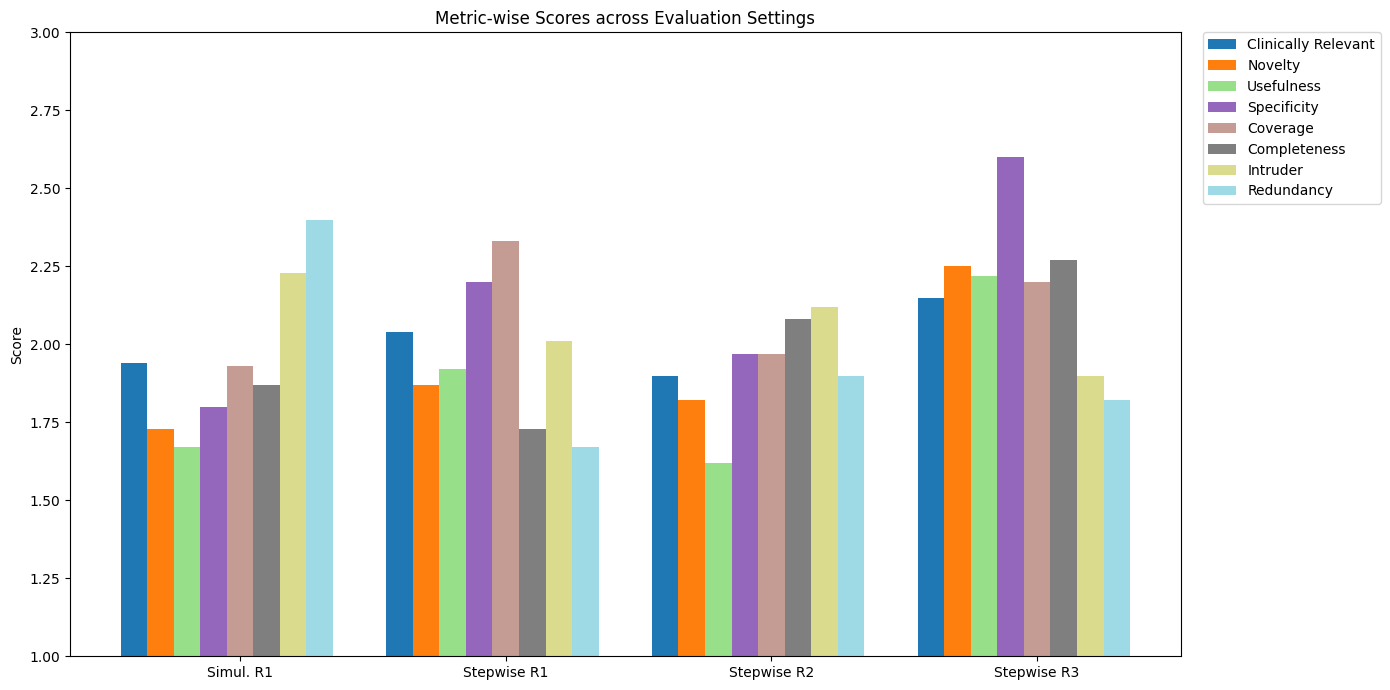

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Metric names and categories
metrics = [
    'Clinically Relevant', 'Novelty', 'Usefulness',         # Insightfulness
    'Specificity', 'Coverage', 'Completeness',              # Trustworthiness
    'Intruder', 'Redundancy'
]
categories = ['Simul. R1', 'Stepwise R1', 'Stepwise R2', 'Stepwise R3']

# Metric values per category (8 metrics x 4 systems)
values = np.array([
    [1.94, 2.04, 1.90, 2.15],  # Clinically Relevant
    [1.73, 1.87, 1.82, 2.25],  # Novelty
    [1.67, 1.92, 1.62, 2.22],  # Usefulness
    [1.80, 2.20, 1.97, 2.60],  # Specificity
    [1.93, 2.33, 1.97, 2.20],  # Coverage
    [1.87, 1.73, 2.08, 2.27],  # Completeness
    [2.23, 2.01, 2.12, 1.90],  # Intruder
    [2.40, 1.67, 1.90, 1.82],  # Redundancy
])

# Plotting
x = np.arange(len(categories))  # label locations
width = 0.1  # width of each bar

fig, ax = plt.subplots(figsize=(14, 7))

# Color palette
colors = plt.cm.tab20(np.linspace(0, 1, len(metrics)))

# Plot each metric with an offset
for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + (i - len(metrics)/2) * width, values[i], width, label=metric, color=color)

# Formatting
ax.set_ylabel('Score')
ax.set_ylim(1, 3)
ax.set_title('Metric-wise Scores across Evaluation Settings')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()


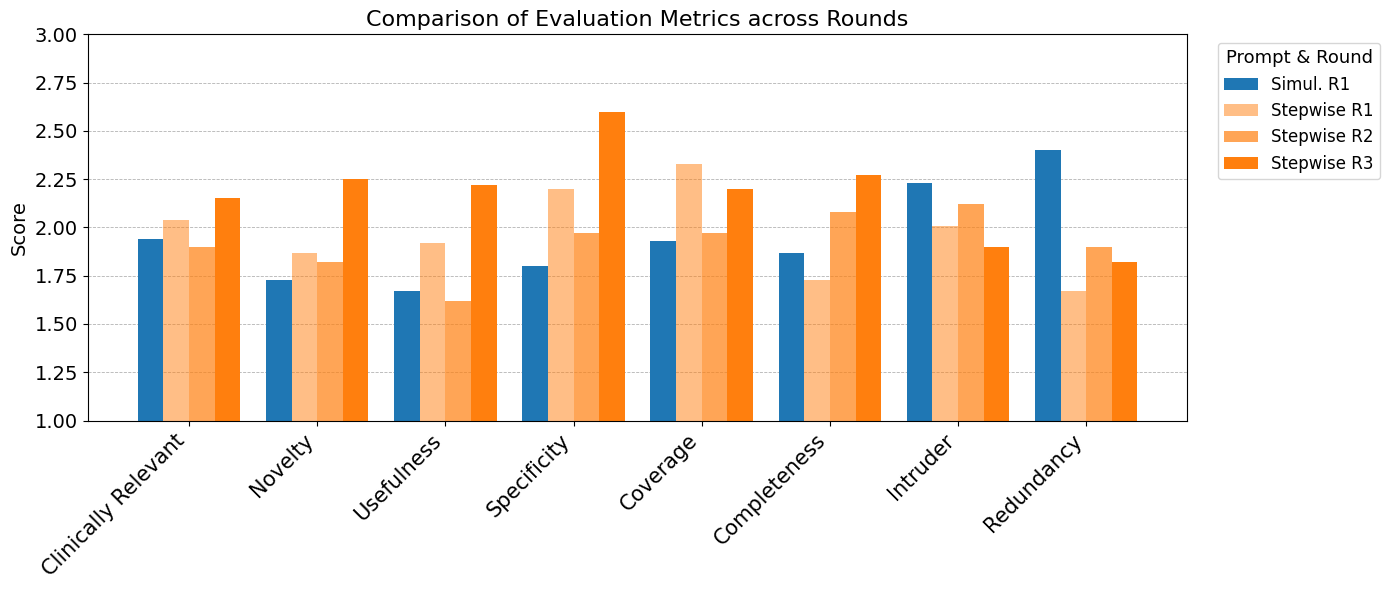

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Define metrics and categories
metrics = [
    'Clinically Relevant', 'Novelty', 'Usefulness',
    'Specificity', 'Coverage', 'Completeness',
    'Intruder', 'Redundancy'
]

categories = ['Simul. R1', 'Stepwise R1', 'Stepwise R2', 'Stepwise R3']

# Metric values per system [8 metrics x 4 categories]
values = np.array([
    [1.94, 2.04, 1.90, 2.15],
    [1.73, 1.87, 1.82, 2.25],
    [1.67, 1.92, 1.62, 2.22],
    [1.80, 2.20, 1.97, 2.60],
    [1.93, 2.33, 1.97, 2.20],
    [1.87, 1.73, 2.08, 2.27],
    [2.23, 2.01, 2.12, 1.90],
    [2.40, 1.67, 1.90, 1.82],
])

# Positioning
x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))

# Colors: Simul blue, Stepwise in shades of orange
simul_color = "#1f77b4"
stepwise_base = "#ff7f0e"
stepwise_shades = [mcolors.to_rgba(stepwise_base, alpha) for alpha in [0.5, 0.7, 1.0]]
colors = [simul_color] + stepwise_shades

# Plot bars
for i, (cat, color) in enumerate(zip(categories, colors)):
    ax.bar(x + i * width - 1.5 * width, values[:, i], width, label=cat, color=color)

# Add grid/raster behind bars
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='gray', alpha=0.6)
ax.set_axisbelow(True)  # Ensure grid is behind the bars

# Formatting with larger, bold fonts
ax.set_ylabel('Score', fontsize=14)
ax.set_ylim(1, 3)
ax.set_title('Comparison of Evaluation Metrics across Rounds', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=45, ha='right', fontsize=15)
ax.tick_params(axis='y', labelsize=12)
ax.yaxis.set_tick_params(labelsize=14)
ax.legend(title='Prompt & Round', title_fontsize=13, fontsize=12, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()


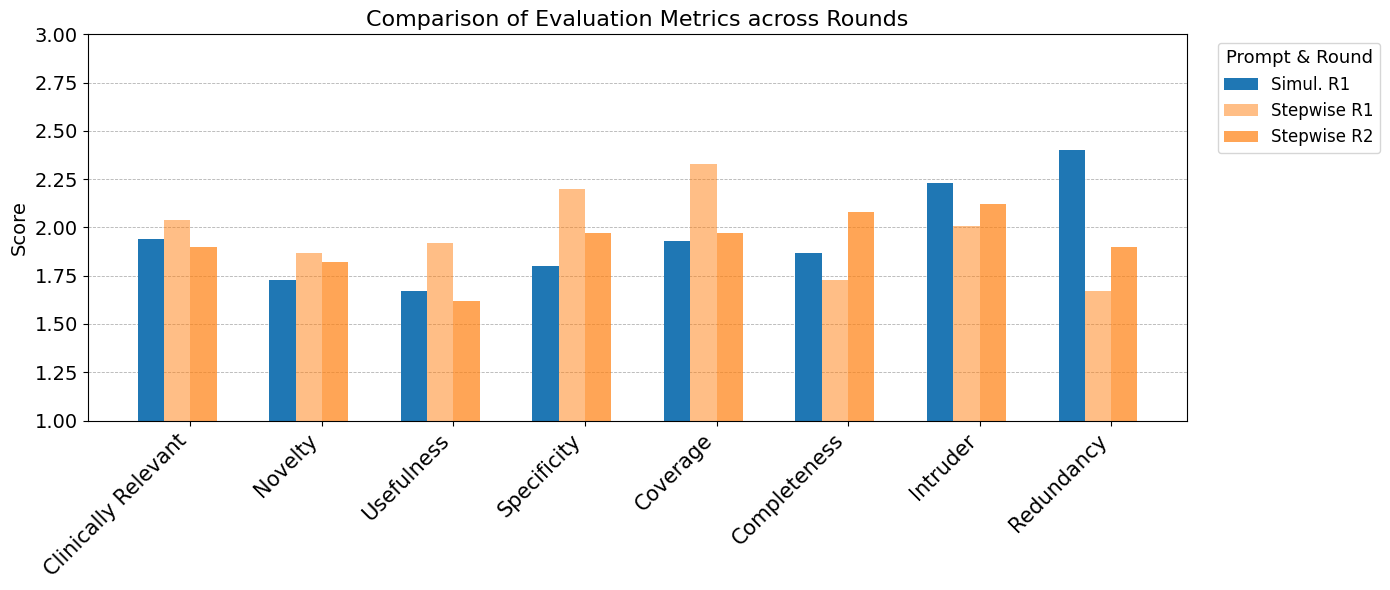

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Define metrics and categories
metrics = [
    'Clinically Relevant', 'Novelty', 'Usefulness',
    'Specificity', 'Coverage', 'Completeness',
    'Intruder', 'Redundancy'
]

categories = ['Simul. R1', 'Stepwise R1', 'Stepwise R2']

# Metric values per system [8 metrics x 4 categories]
values = np.array([
    [1.94, 2.04, 1.90],
    [1.73, 1.87, 1.82],
    [1.67, 1.92, 1.62],
    [1.80, 2.20, 1.97],
    [1.93, 2.33, 1.97],
    [1.87, 1.73, 2.08],
    [2.23, 2.01, 2.12],
    [2.40, 1.67, 1.90],
])

# Positioning
x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))

# Colors: Simul blue, Stepwise in shades of orange
simul_color = "#1f77b4"
stepwise_base = "#ff7f0e"
stepwise_shades = [mcolors.to_rgba(stepwise_base, alpha) for alpha in [0.5, 0.7, 1.0]]
colors = [simul_color] + stepwise_shades

# Plot bars
for i, (cat, color) in enumerate(zip(categories, colors)):
    ax.bar(x + i * width - 1.5 * width, values[:, i], width, label=cat, color=color)

# Add grid/raster behind bars
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='gray', alpha=0.6)
ax.set_axisbelow(True)  # Ensure grid is behind the bars

# Formatting with larger, bold fonts
ax.set_ylabel('Score', fontsize=14)
ax.set_ylim(1, 3)
ax.set_title('Comparison of Evaluation Metrics across Rounds', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=45, ha='right', fontsize=15)
ax.tick_params(axis='y', labelsize=12)
ax.yaxis.set_tick_params(labelsize=14)
ax.legend(title='Prompt & Round', title_fontsize=13, fontsize=12, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()


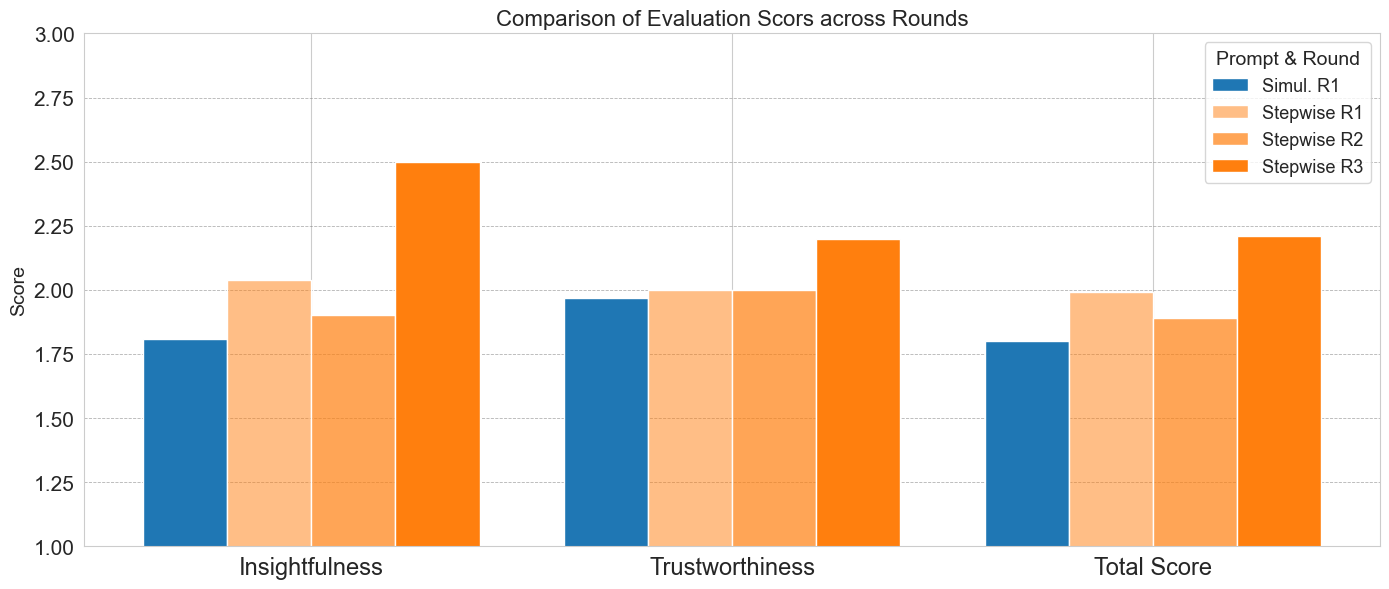

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

# Define metrics and categories
metrics = [
    'Insightfulness', 'Trustworthiness', 'Total Score'
]

categories = ['Simul. R1', 'Stepwise R1', 'Stepwise R2', 'Stepwise R3']

# Metric values per system [8 metrics x 4 categories]
values = np.array([
    [1.81, 2.04, 1.90, 2.50],
    [1.97, 2.00, 2.00, 2.20],
    [1.80, 1.99, 1.89, 2.21]
])

# Positioning
x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))

# Colors: Simul blue, Stepwise in shades of orange
simul_color = "#1f77b4"
stepwise_base = "#ff7f0e"
stepwise_shades = [mcolors.to_rgba(stepwise_base, alpha) for alpha in [0.5, 0.7, 1.0]]
colors = [simul_color] + stepwise_shades

# Plot bars
for i, (cat, color) in enumerate(zip(categories, colors)):
    ax.bar(x + i * width - 1.5 * width, values[:, i], width, label=cat, color=color)

# Add grid/raster behind bars
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='gray', alpha=0.6)
ax.set_axisbelow(True)  # Ensure grid is behind the bars

# Formatting with larger, bold fonts
ax.set_ylabel('Score', fontsize=14)
ax.set_ylim(1, 3)
ax.set_title('Comparison of Evaluation Scors across Rounds', fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=17)
ax.tick_params(axis='y', labelsize=13)
ax.yaxis.set_tick_params(labelsize=15)
ax.legend(title='Prompt & Round', title_fontsize=14, fontsize=13, loc='upper right')

plt.tight_layout()
plt.show()


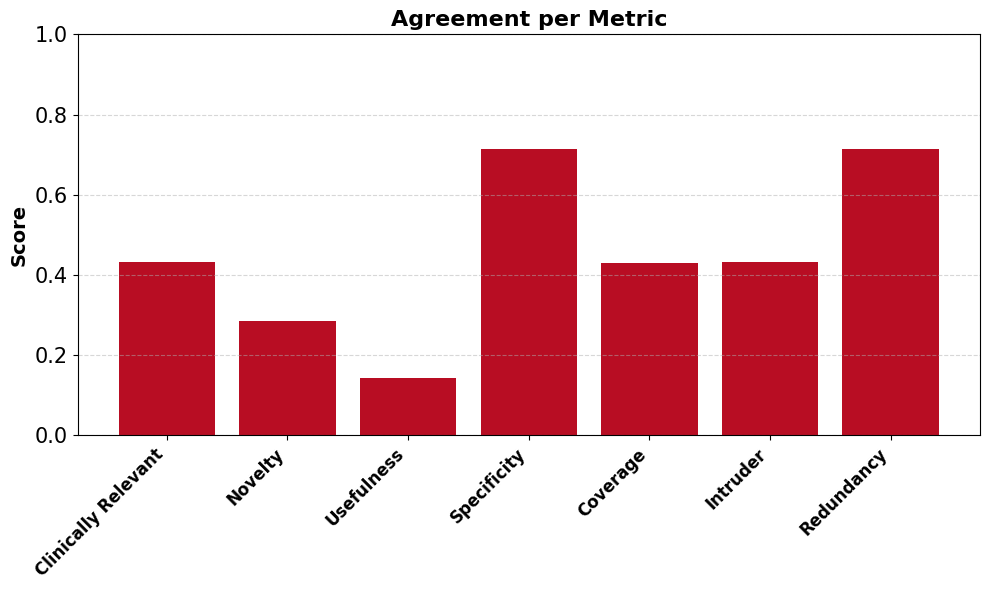

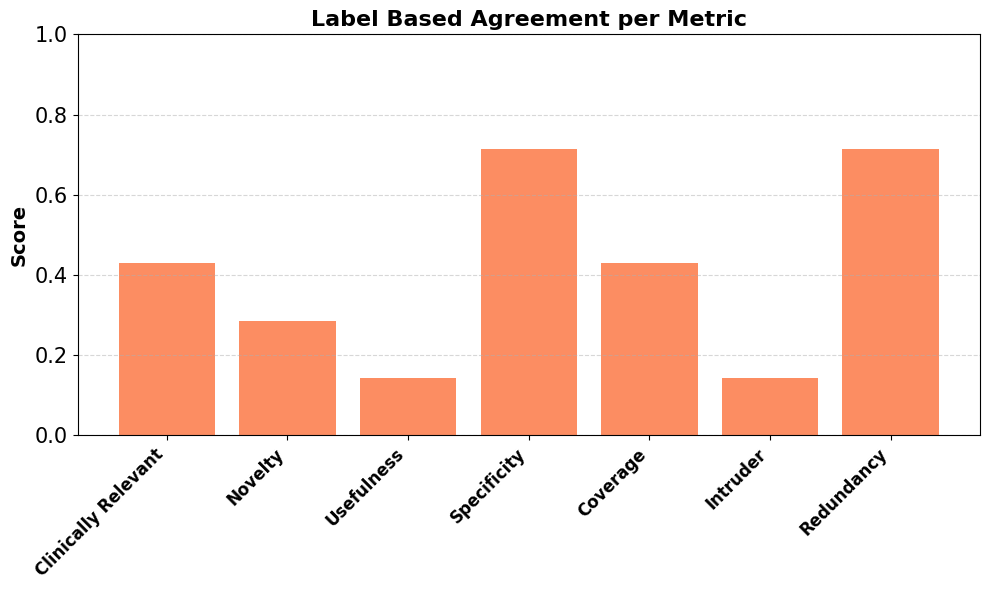

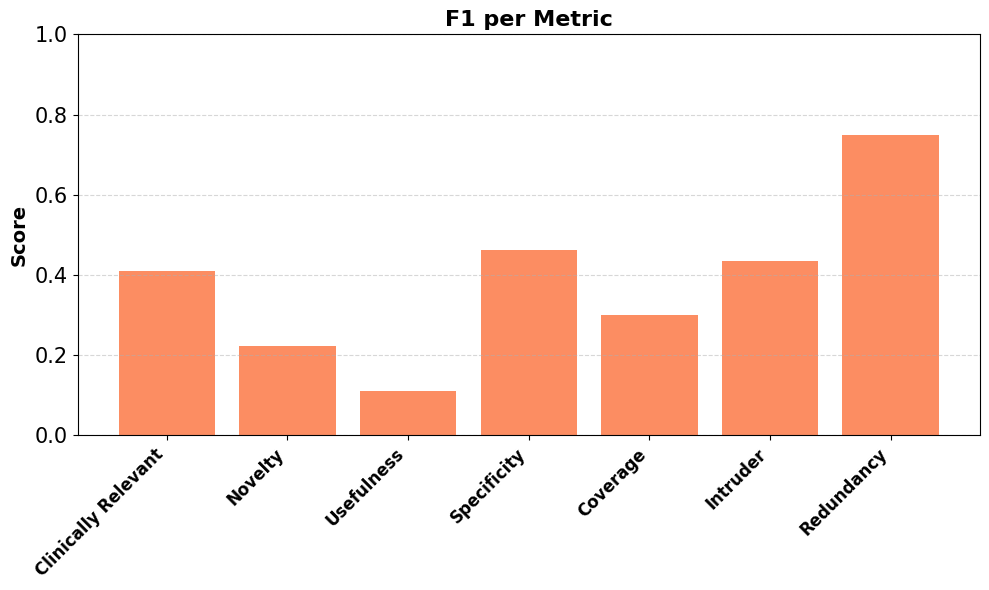

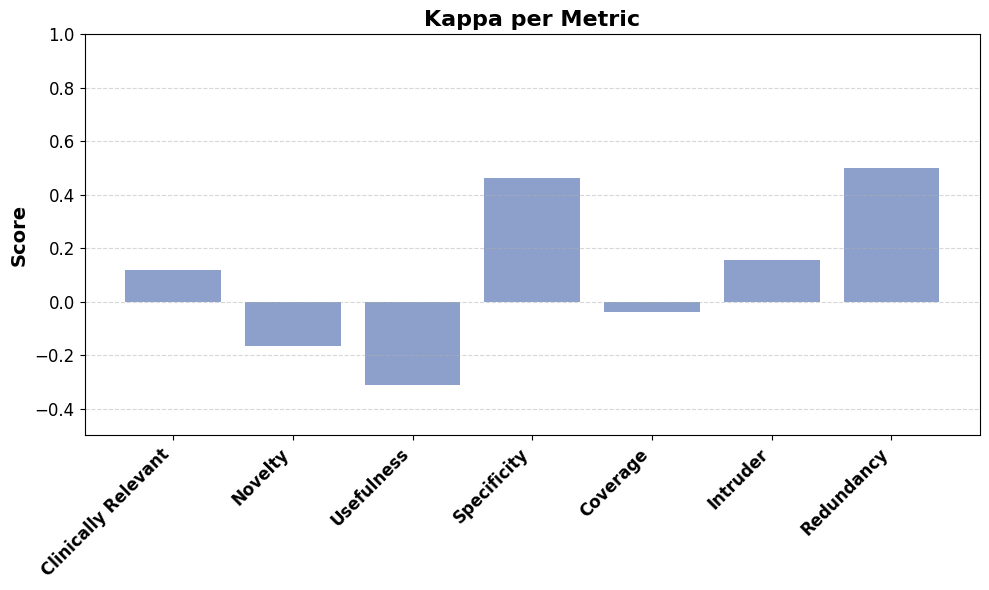

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the table
metrics = ['Clinically Relevant', 'Novelty', 'Usefulness', 'Specificity', 'Coverage', 'Intruder', 'Redundancy']
agreement = [0.433, 0.286, 0.143, 0.714, 0.429, 0.433, 0.714]
f1 = [0.409, 0.222, 0.111, 0.463, 0.300, 0.434, 0.750]
kappa = [0.119, -0.167, -0.312, 0.462, -0.037, 0.156, 0.500]
label_based_agreement = [0.429, 0.286, 0.143, 0.714, 0.429, 0.143, 0.714]

# Plotting function
def plot_measure(title, values, color):
    plt.figure(figsize=(10, 6))
    plt.bar(metrics, values, color=color)
    plt.title(f'{title} per Metric', fontsize=16, fontweight='bold')
    plt.ylabel('Score', fontsize=14, fontweight='bold')
    plt.ylim(-0.5, 1)
    plt.xticks(rotation=45, ha='right', fontsize=12, fontweight='bold')
    plt.yticks(fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

def plot_measure_no_negative(title, values, color):
    plt.figure(figsize=(10, 6))
    plt.bar(metrics, values, color=color)
    plt.title(f'{title} per Metric', fontsize=16, fontweight='bold')
    plt.ylabel('Score', fontsize=14, fontweight='bold')
    plt.ylim(0, 1)
    plt.xticks(rotation=45, ha='right', fontsize=12, fontweight='bold')
    plt.yticks(fontsize=15)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


# Generate one figure per measure
plot_measure_no_negative("Agreement", agreement, "#B80D23")
plot_measure_no_negative("Label Based Agreement", label_based_agreement, "#fc8d62")
plot_measure_no_negative("F1", f1, "#fc8d62")
plot_measure("Kappa", kappa, "#8da0cb")
